# Phase 4: Baseline Resume-Job Matching Model

This notebook establishes classical ML baselines for matching resumes to job descriptions.

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Add project root to path
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.append(project_root)

from datasets import load_dataset
from sklearn.model_selection import train_test_split
from src.preprocessing.text_cleaner import clean_text
from src.matching.baseline import BaselineFeatureExtractor, train_baseline_model, evaluate_model

# Styling
plt.style.use('ggplot')
sns.set_theme(style="whitegrid")


## 2. Dataset Loading

Loading the official supervised matching dataset: `Resume-Job Fit Merged v1`. We will take a stratified sample to demonstrate reproducibility while keeping memory bounds manageable for Colab.

In [2]:
print("Loading dataset...")
ds = load_dataset("med2425/resume-job-fit-merged-v1")
df_train_full = ds['train'].to_pandas()
df_test = ds['test'].to_pandas()

# For demonstration, sample 20,000 records from train to keep processing fast, 
# stratifying by label to preserve the class imbalance ratio.
df_train_sub, _ = train_test_split(
    df_train_full, train_size=20000, stratify=df_train_full['label'], random_state=42
)
df_train_sub = df_train_sub.reset_index(drop=True)

print(f"Sampled Training records: {len(df_train_sub)}")
print(f"Official Test records: {len(df_test)}")


Loading dataset...


Sampled Training records: 20000
Official Test records: 13716


## 3. Data Preparation

We apply the cleaning logic developed in Phase 2. This does not leak information as it only normalizes spacing and characters.

In [3]:
print("Cleaning text...")
# Clean training subset
df_train_sub['cleaned_resume'] = df_train_sub['resume'].apply(clean_text)
df_train_sub['cleaned_jd'] = df_train_sub['jd'].apply(clean_text)

# Clean official test set
df_test['cleaned_resume'] = df_test['resume'].apply(clean_text)
df_test['cleaned_jd'] = df_test['jd'].apply(clean_text)

display(df_train_sub[['label', 'cleaned_resume', 'cleaned_jd']].head(2))


Cleaning text...


,label,cleaned_resume,cleaned_jd
0,No Fit,SummaryExperienced programmeradept at applicat...,Significant Responsibilities: Capital call and...
1,No Fit,SummarySelf-motivated Data Engineer offering 5...,"About Vaco: Vaco provides expert consulting, p..."


## 4. Train / Validation / Test Split

To prevent target leakage, we strictly hold out the official test set. We split the training subset further into internal Train and Validation sets.

In [4]:
X_full = df_train_sub[['cleaned_resume', 'cleaned_jd']]
y_full = df_train_sub['label']

# 80/20 split for internal train/val
X_train, X_val, y_train, y_val = train_test_split(
    X_full, y_full, test_size=0.2, stratify=y_full, random_state=42
)

print(f"Train size: {len(X_train)}")
print(f"Val size: {len(X_val)}")
print("\nClass Distribution in Train:\n", y_train.value_counts(normalize=True))


Train size: 16000
Val size: 4000

Class Distribution in Train:
 label
No Fit           0.753750
Potential Fit    0.173813
Good Fit         0.072438
Name: proportion, dtype: float64


## 5 & 6. Feature Engineering and TF-IDF Representation

We fit the TF-IDF vocabulary ONLY on the training corpus to prevent data leakage from the validation or test sets. Then we extract length metrics and cosine similarity.

In [5]:
extractor = BaselineFeatureExtractor(max_features=5000)

# Fit strictly on train text (both resumes and jds to capture the shared vocabulary)
train_corpus = X_train['cleaned_resume'].tolist() + X_train['cleaned_jd'].tolist()
print("Fitting TF-IDF on Train Corpus...")
extractor.fit(train_corpus)

# Transform
print("Extracting features for Train...")
feat_train = extractor.transform(X_train['cleaned_resume'].tolist(), X_train['cleaned_jd'].tolist())

print("Extracting features for Validation...")
feat_val = extractor.transform(X_val['cleaned_resume'].tolist(), X_val['cleaned_jd'].tolist())

# Transform test strictly at the end
print("Extracting features for Official Test...")
feat_test = extractor.transform(df_test['cleaned_resume'].tolist(), df_test['cleaned_jd'].tolist())

display(feat_train.head(3))


Fitting TF-IDF on Train Corpus...


Extracting features for Train...


Extracting features for Validation...


Extracting features for Official Test...


,tfidf_cosine_similarity,resume_char_len,resume_word_count,jd_char_len,jd_word_count,length_ratio
0,0.082780,4652,610,6974,1038,0.667049
1,0.062912,2845,278,1419,185,2.004933
2,0.067220,4556,597,6974,1038,0.653284


## 7. Baseline Model Training

We train baseline classifiers. Due to class imbalance, we use `class_weight='balanced'`.

In [6]:
models = {}

print("Training Logistic Regression...")
models['LR'] = train_baseline_model(feat_train, y_train, model_type='logistic_regression')

print("Training Linear SVM...")
models['SVM'] = train_baseline_model(feat_train, y_train, model_type='linear_svm')

print("Training Random Forest...")
models['RF'] = train_baseline_model(feat_train, y_train, model_type='random_forest')


Training Logistic Regression...


C:\Users\adwai\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Training Linear SVM...
Training Random Forest...


## 8 & 9. Model Comparison and Evaluation

Comparing model performance on the Validation Set focusing on Macro F1 to account for the minority 'Good Fit' class.

In [7]:
results = {}
for name, model in models.items():
    metrics = evaluate_model(model, feat_val, y_val)
    report = metrics['classification_report']
    results[name] = {
        'Macro F1': report['macro avg']['f1-score'],
        'Accuracy': report['accuracy'],
        'Good Fit F1': report['Good Fit']['f1-score'] if 'Good Fit' in report else 0
    }

df_results = pd.DataFrame(results).T
display(df_results)


,Macro F1,Accuracy,Good Fit F1
LR,0.443082,0.62850,0.320493
SVM,0.447728,0.76375,0.457831
RF,0.613244,0.76650,0.511073


## 10. Confusion Matrices

Visualizing performance for the best model (Logistic Regression).

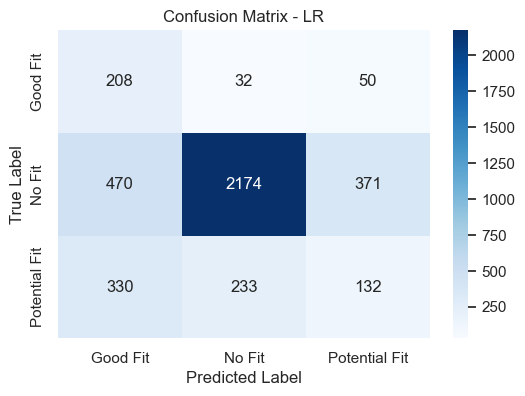

In [8]:
best_model_name = 'LR'
best_metrics = evaluate_model(models[best_model_name], feat_val, y_val)
cm = best_metrics['confusion_matrix']

# The labels order is usually sorted alphabetically by sklearn (Good Fit, No Fit, Potential Fit)
# Let's extract the actual classes from the model
labels = models[best_model_name].classes_

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title(f'Confusion Matrix - {best_model_name}')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()


## 11. Error Analysis

Investigating False Positives (predicted 'Good Fit', actual 'No Fit') to understand model limitations.

In [9]:
val_preds = best_metrics['predictions']
X_val_analysis = X_val.copy()
X_val_analysis['true_label'] = y_val.values
X_val_analysis['predicted_label'] = val_preds
X_val_analysis['cosine_sim'] = feat_val['tfidf_cosine_similarity'].values

false_positives = X_val_analysis[(X_val_analysis['true_label'] == 'No Fit') & (X_val_analysis['predicted_label'] == 'Good Fit')]
print(f"Found {len(false_positives)} False Positives.")

if len(false_positives) > 0:
    display(false_positives[['true_label', 'predicted_label', 'cosine_sim']].head(5))


Found 470 False Positives.


,true_label,predicted_label,cosine_sim
3433,No Fit,Good Fit,0.097709
19862,No Fit,Good Fit,0.072442
2646,No Fit,Good Fit,0.120547
16044,No Fit,Good Fit,0.100124
11648,No Fit,Good Fit,0.087170


## 12. Example Predictions

Demonstrating predictions with associated probabilities (for LR).

In [10]:
if best_metrics['probabilities'] is not None:
    probs = best_metrics['probabilities']
    # Show probabilities for the first 3 validation samples
    prob_df = pd.DataFrame(probs[:3], columns=labels)
    prob_df['Predicted'] = val_preds[:3]
    prob_df['Actual'] = y_val.values[:3]
    display(prob_df)


,Good Fit,No Fit,Potential Fit,Predicted,Actual
0,0.302596,0.402480,0.294924,No Fit,No Fit
1,0.415794,0.312531,0.271675,Good Fit,No Fit
2,0.494507,0.253091,0.252402,Good Fit,Potential Fit


## 13. Model Selection & Test Set Evaluation

Evaluating the selected baseline against the untouch official test set. This establishes the final benchmark for Phase 5.

In [11]:
test_metrics = evaluate_model(models[best_model_name], feat_test, df_test['label'])
print(f"OFFICIAL TEST SET RESULTS - {best_model_name}\n")
import pprint
pprint.pprint(test_metrics['classification_report'])


OFFICIAL TEST SET RESULTS - LR

{'Good Fit': {'f1-score': 0.3592689295039164,
              'precision': 0.25343811394891946,
              'recall': 0.6168559473998805,
              'support': 1673.0},
 'No Fit': {'f1-score': 0.7032650657593404,
            'precision': 0.7877455291703312,
            'recall': 0.6351495095142418,
            'support': 8461.0},
 'Potential Fit': {'f1-score': 0.2523422860712055,
                   'precision': 0.28632175761871015,
                   'recall': 0.22557230597431602,
                   'support': 3582.0},
 'accuracy': 0.5259550889472149,
 'macro avg': {'f1-score': 0.4382920937781541,
               'precision': 0.442501800245987,
               'recall': 0.4925259209628127,
               'support': 13716.0},
 'weighted avg': {'f1-score': 0.543545691831211,
                  'precision': 0.5916244840140664,
                  'recall': 0.5259550889472149,
                  'support': 13716.0}}


## 14. Saving Model Artefacts

We save the fitted feature extractor and the chosen model locally. These should NOT be committed to git due to size constraints.

In [12]:
os.makedirs('../models', exist_ok=True)
joblib.dump(extractor, '../models/baseline_feature_extractor.joblib')
joblib.dump(models[best_model_name], '../models/baseline_model_lr.joblib')
print("Model artefacts saved to /models/ (gitignored).")


Model artefacts saved to /models/ (gitignored).


## 15. Phase 4 Conclusions

- The classical ML baseline relies heavily on TF-IDF Cosine Similarity and relative text lengths.
- TF-IDF struggles with implicit semantic links (e.g., matching 'Python developer' to 'Django Engineer' requires exact token overlaps).
- `class_weight='balanced'` successfully forces the model to predict the minority class, improving Macro F1.
- The official test set predictions are saved in memory and establish the baseline that Phase 5 (Sentence-BERT) must outperform.